In [100]:
import torch
import numpy as np

from sklearn.datasets import load_wine
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.metrics import f1_score, accuracy_score
from torch import Tensor
from torch.nn import Sequential, Linear, ReLU, MSELoss, CrossEntropyLoss, Module
from torch.utils.data import DataLoader, Dataset
from torch.optim import Adam
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt


In [101]:
class MyDataset(Dataset):
    def __init__(self, datas: np.ndarray, labels: np.ndarray) -> None:
        self._x = torch.from_numpy(datas).float()
        self._y = torch.from_numpy(labels).long()

    def __len__(self) -> int:
        return len(self._x)

    def __getitem__(self, idx: int) -> tuple[Tensor, Tensor]:
        int(idx)
        return self._x[idx], self._y[idx]

In [102]:
class CustomModel(Module):
    def __init__(self, input_size: int, output_size) -> None:
        super().__init__()
        self.net = Sequential(
            Linear(input_size, 32),
            ReLU(),
            Linear(32,16),
            ReLU(),
            Linear(16, output_size)
        )

    def forward(self, x: Tensor) -> Tensor:
        return self.net(x)

In [103]:
def train_model_class(X, Y, skf, batch, epochs, criterion, exp=False):
    f1_scores = []
    accuracy_scores = []
    folds_loss = []
    folds_acc = []
    for i, (train_index, test_index) in enumerate(skf.split(X, Y)):
        print(f"Treinando modelo ----- Fold {i + 1}")
        
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X[train_index])
        X_test_scaled = scaler.transform(X[test_index])

        train_data = MyDataset(X_train_scaled, Y[train_index])
        train_loader = DataLoader(train_data, batch_size=batch)
        model = CustomModel(13, 3)
        optmizer = Adam(model.parameters(), lr=0.001)
        epoch_loss = []
        epoch_acc = []
        
    
        for i_epochs in range(epochs):    
            model.train()
            for x, y in train_loader:
                batches_loss = []
                batches_acc = []
                optmizer.zero_grad()
                output = model(x).cpu()
                loss = criterion(output, y)
                loss.backward()
                optmizer.step()
                batches_loss.append(loss.item())
                batches_acc.append(accuracy_score(y, torch.argmax(output, dim=1).cpu().numpy()))
            epoch_loss.append(np.mean(batches_loss))
            epoch_acc.append(np.mean(batches_acc))

        folds_loss.append(epoch_loss)
        folds_acc.append(epoch_acc)

        model.eval()
        with torch.no_grad():
            x_test_tensor = Tensor(X_test_scaled).float()
            output = model(x_test_tensor).cpu()
            result = torch.argmax(output, dim=1).cpu().numpy()
            f1_s = f1_score(Y[test_index], result, average="macro")
            accuracy_s = accuracy_score(Y[test_index], result)
            f1_scores.append(f1_s)
            accuracy_scores.append(accuracy_s)
            print(f"f1: {f1_s}")
            print(f"Accuracy: {accuracy_s}")

        if exp:
             break

    print(f"\nResultado modelo ----- F1: {np.mean(f1_scores)},  accuracy:{np.mean(accuracy_scores)}")

    return folds_loss, folds_acc

In [104]:
def plot_loss(folds_loss, folds_acc):
    for idx, fold_l in enumerate(folds_loss):
        fig, ax1 = plt.subplots(figsize=(7, 3))
        x = np.linspace(0, len(fold_l), len(fold_l))
        
        ax1.plot(x, fold_l, color="red", label="Erro")
        ax1.set_xlabel("Épocas")
        ax1.set_ylabel("Erro")
        ax1.set_ylim(0, np.max(fold_l) * 1.1)  # Ajusta o limite superior dinamicamente
        
        ax2 = ax1.twinx()
        acc_percent = np.array(folds_acc[idx]) * 100  # Conversão correta para %
        ax2.plot(x, acc_percent, color="blue", label="Acc")
        ax2.set_ylabel("Acurácia (%)")
        ax2.set_ylim(0, 105)
        ax2.grid(True)
        
        fig.legend(loc="upper right")
        plt.show()

In [105]:
dataset = load_wine()
X = dataset.data
Y = dataset.target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [106]:
print(X.shape)

(178, 13)


In [107]:
model = Sequential(
    Linear(13, 32),
    ReLU(),
    Linear(32,16),
    ReLU(),
    Linear(16, 3)
)

In [108]:

criterion = CrossEntropyLoss()
max_epochs = 500
batch = 16
skf = StratifiedKFold(n_splits=5, shuffle=True,  random_state=42)

In [109]:
folds_loss, folds_acc = train_model_class(X, Y, skf, batch, max_epochs, criterion, True)

Treinando modelo ----- Fold 1
f1: 0.9717813051146384
Accuracy: 0.9722222222222222

Resultado modelo ----- F1: 0.9717813051146384,  accuracy:0.9722222222222222


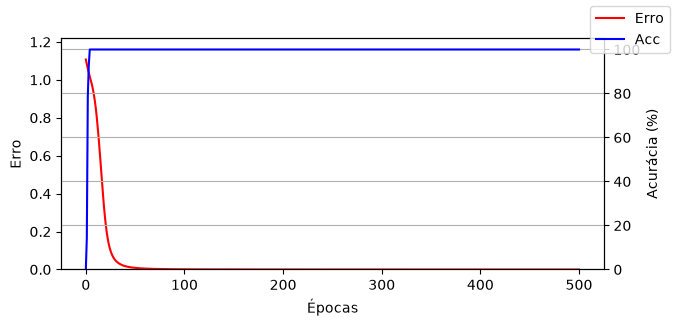

In [110]:
plot_loss(folds_loss, folds_acc)